### Cronograma

| Etapa | Descrição | Resultado esperado |
|---|---|---|
| 0 | Definição do benchmark | Problema de referência, parâmetros e critérios de validação |
| 1 | Formulação matemática e Arquitetura | Equações, hipóteses, domínio, condições de contorno e bibliotecas|
| 2 | Discretização espacial e Temporal | Malha escalonada, operadores e ELM |
| 3 | Construção do sistema linear | Montagem de \(A\eta=b\) e verificação da esparsidade. Matriz pentadiagonal e operador Matrix-Free |
| 4 | Implementação dos solucionadores | PCG, PCG-Jacobi e Thomas/ADI |
| 5 | Reprodução numérica de Casulli | Resultados nas malhas 40×20 e 60×120 |
| 6 | Implementação em JAX | Portabilidade para CPU e GPU |
| 7 | Análise espectral e escalabilidade | Autovalores, condicionamento, desempenho e refinamento |
| 8 | Discussão dos resultados  | Comparações e conclusões |

# Etapa 0 - Definição  do Problema e Benchmark

De início, é necessário definir uma referência que permita testar e, idealmente, demonstrar que a implementação está correta. Vale ressaltar que isso é composto por dois objetivos complementares e diferentes: validar a formulação física e formular o algoritmo de solução do sistema linear.

Como referência principal será utilizada ["Semi-implicit finite difference methods for the two-dimensional shallow water equations" (Casulli, 1990)](https://doi.org/10.1016/0021-9991(90)90091-E), que estabelece uma abordagem matemática e algorítmica para simuladores hidrodinâmicos, abordando a resolução numérica das Equações de Águas Rasas Bidimensionais (2D Shallow Water Equations - SWE).

Esse sistema de equações descreve o escoamento de um fluido incompressível com superfície livre (como oceanos costeiros, estuários, grandes lagos, rios largos, mares continentais) sob a hipótese hidrostática (a pressão em qualquer ponto da coluna d'água é determinado exclusivamente pelo peso da coluna de fluido acima dele, ignorando os efeitos das acelerações verticais). Essa hipótese é válida quando a escala horizontal do escoamento (comprimento de onda) é muito maior que a profundidade vertical da coluna d'água,

$$\frac{H}{L} \ll 1$$

onde $H$ é a escala de profundidade vertical e $L$ a escala de comprimento horizontal característico (daí "águas rasas"). Em casos como, por exemplo, perto de pilastras de pontes, situações com forte turbulência vertical, convecção profunda com aceleração vertical do fluido, exigem o uso das equações de Navier-Stokes tridimensionais.

As SWE formam um sistema quasilenear hiperbólico de equações diferenciais parciais em três variáveis independentes $(x,y,t)$ ("quasilinear" porque é linear em relção às derivadas de ordem mais alta, mas os coeficientes dessas derivadas podem  depender das variáveis independentes e das próprias variáveis dependentes desconhecidas; "hiperbólico" porque o problema de valor inicial é bem posto, no sentido de o problema possuir solução única que depende continuamente dos dados iniciais e todas as perturbações iniciais se propagam a velocidades reais e finitas ao longo das curvas e superfícies características):

$$
\begin{array}{lc}
  \dfrac{\partial u}{\partial t} + u\dfrac{\partial u}{\partial x} + v\dfrac{\partial u}{\partial y} = -g\dfrac{\partial z}{\partial x} -\gamma u + \tau_x & \qquad (1) \\[8pt]
  \dfrac{\partial v}{\partial t} + u\dfrac{\partial v}{\partial x} + v\dfrac{\partial v}{\partial y} = -g\dfrac{\partial z}{\partial y} -\gamma v + \tau_y & \qquad (2) \\[8pt]
  \dfrac{\partial z}{\partial t} + \dfrac{\partial [(h+z)u]}{\partial x} + \dfrac{\partial [(h+z)v]}{\partial y} = 0 & \qquad (3)
\end{array}
$$

onde:

* $u(x,y,t)$ e $v(x,y,t)$ são as componentes da velocidade do fluido mediadas na profundidade, respectivamente nas direções $x$ e $y$;
* $z(x,y,t)$ é a elevação da superfície livre da água medida a partir de um nível de referência não perturbado;
* $h(x,y)$ é a profundidade da água também medida a partir de um nível de referência não perturbado;
* $g$, constante de aceleração da gravidade;
* $\tau_x$ e $\tau_y$ são os termos de estresse do vento nas direções $x$ e $y$, respectivamente;
* $\gamma$ é o coeficiente de atrito com o fundo, dado pela equação,

$$\gamma = \frac{g\sqrt{u^2 + v^2}}{C_z^2H}$$

sendo, $H(x,y,t) = h(x,y) + z(x,y,t)$ a profundidade total da água e $C_z$ o coeficiente de fricção de Chezy, que mede a capacidade de resistência ao escoamento imposta pelo leito sobre a velocidade média na vertical $(u,v)$ e a profundidade total $H$.

<figure align="center">
  <figcaption><strong>Figura 1: Domínio Físico, Escalas e Variáveis das Equações de Águas Rasas Bidimensionais (2D SWE)</strong></figcaption>
  <img src="../figures/swe_physical_domain.svg?v=4" alt="Domínio Físico, Escalas e Variáveis das Equações de Águas Rasas Bidimensionais (2D SWE)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

Definindo o vetor velocidade horizontal $\vec{u} = (u, v)$ e o vetor de forçamento externo $\vec{\tau} = (\tau_x, \tau_y)$, usando o operador diferencial vetorial $\nabla = \left( \frac{\partial}{\partial x}, \frac{\partial}{\partial y}\right)$, temos as equações de águas rasas na forma semi-compacta

$$
\begin{array}{lc}
  \dfrac{\partial u}{\partial t} + \vec{u}\cdot \nabla u = -g(\nabla z)_x - \gamma u + \tau_x  & \qquad (4) \\[8pt]
  \dfrac{\partial v}{\partial t} + \vec{u}\cdot \nabla v = -g(\nabla z)_y - \gamma v + \tau_y & \qquad (5) \\[8pt]
  \dfrac{\partial z}{\partial t} + \nabla \cdot [(h + z)\vec{u}] = 0 & \qquad (6)
\end{array}
$$

e, em forma compacta total,

$$
\begin{array}{lc}
  \dfrac{\partial \vec{u}}{\partial t} + (\vec{u}\cdot \nabla)\vec{u} = -g\nabla z - \gamma \vec{u} + \vec{\tau} & \qquad (7) \\[8pt]
  \dfrac{\partial z}{\partial t} + \nabla \cdot [(h + z)\vec{u}] = 0 & \qquad (8) \\[8pt]
\end{array}
$$

### 0.1. Significado das equações

Na primeira equação $(1)$,

$$\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} + v\frac{\partial u}{\partial y} = -g\frac{\partial z}{\partial x} -\gamma u + \tau_x$$

no lado esquerdo, temos um conjunto de derivadas parciais que medem a mudança da velocidade $u$ no tempo $\frac{\partial u}{\partial t}$ e no campo espacial $x \times y$ onde $u$ varia: $\frac{\partial u}{\partial x}$ e $\frac{\partial u}{\partial y}$. No lado direito, sobre o termo $-g\frac{\partial z}{\partial x}$, como, pelo princípio hidrostático a pressão varia unicamente em função da coluna de água, a pressão horizontal depende da inclinação da superfície livre $z(x,y,t)$:

* Se a superfície da água está mais alta à esquerda e mais baixa a direita, então $\frac{\partial z}{\partial x} < 0$ e $-g\frac{\partial z}{\partial x} > 0$: a gravidade desloca a água da posição mais alta para a mais baixa, acelerando $u$ para a direita.
* Este termo impulsiona ou freia conforme o sinal da inclinação $\frac{\partial z}{\partial x}$.

Ainda na direita, o termo $-\gamma u$ atua como dissipação/amortecimento por atrito, opondo-se ao movimento, dado $\gamma \ge 0$. Por fim, $\tau_x$ um forçamento externo pelo vento na superfície, podendo acelerar ou desacelerar conforme a direção do vento.

<figure align="center">
  <figcaption><strong>Figura 2: Significado Físico e Dinâmico da Equação de Quantidade de Movimento na Direção x</strong></figcaption>
  <img src="../figures/swe_momentum_x_meaning.svg?v=4" alt="Significado Físico e Dinâmico da Equação de Quantidade de Movimento na Direção x" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

Na segunda equação $(2)$,

$$\frac{\partial v}{\partial t} + u\frac{\partial v}{\partial x} + v\frac{\partial v}{\partial y} = -g\frac{\partial z}{\partial y} -\gamma v + \tau_y$$

a lógica é exatamente a mesma, mas para a componente $v$ na horizontal $y$.

A terceira equação $(3)$,

$$\frac{\partial z}{\partial t} + \frac{\partial [(h+z)u]}{\partial x} + \frac{\partial [(h+z)v]}{\partial y} = 0$$

descreve o sobe-e-desce $\frac{\partial z}{\partial t}$ com conservação de massa para um fluido incomprensível, ou seja, sem evaporação, sem chuva ou infiltração, daí ser igual a $0$. Podemos reescrevê-la como

$$\frac{\partial z}{\partial t} = -\left(\frac{\partial [(h + z)u]}{\partial x} + \frac{\partial [(h + z)v]}{\partial y}\right)$$

onde $(h + z)x$ e $(h + z)v$ são os fluxos volumétricos por unidade de largura nas direções $x$ e $y$, ou seja, a profundidade total vezes a velocidade. Se entra mais água do que sai na coluna d'água, o divergente do fluxo é negativo, o lado direito torna-se positivo e $\frac{\partial z}{\partial t} > 0$, logo, a coluna de água sobe; se o gradiante for positivo, a coluna de água desce.

<figure align="center">
  <figcaption><strong>Figura 3: Significado Físico da Equação da Continuidade (Conservação de Massa e Sobe-e-Desce da Superfície Livre)</strong></figcaption>
  <img src="../figures/swe_continuity_meaning.svg?v=2" alt="Significado Físico da Equação da Continuidade (Conservação de Massa e Sobe-e-Desce da Superfície Livre)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

### 0.2. Análise de Características

Quando uma superfície fluida em equilíbrio sofre uma perturbação inicial, seja no fluxo, seja na elevação, dois fenômenos ocorrem simultaneamente:

1. O próprio fluido se desloca (advecção) com velocidade $\vec{u} = (u, v)$.
2. Uma onda de gravidade superficial se espalha circularmente a partir do ponto de perturbação com velocidade $c = \sqrt{gH}$.

Em determinados cenários, como oceanos e canais, por exemplo, a velocidade da onda $c = \sqrt{gH}$ pode ser várias ordens de magnitude maior do que a velocidade da corrente ($|u|$, $|v|$). Para lidar com a diferença de escalas em uma simulação é necessário responder duas perguntas:

* Quais são exatamente todas as velocidades e direções de propagação de perturbação/informação contidas nas equações?
* Quais termos específicos da equação produzem as ondas rápidas ($\sqrt{gH}$) e quais produzem o transporte lento ($\vec{u}$)?

Separar matematicamente esses dois comportamentos torna a simulação mais eficiente. Em vez de usar um método computacional único, talvez pesado, para resolver a equação inteira, o ideal é separar um método apenas para os termos das ondas rápidas, responsáveis pela restrição de estabilidade numérica em esquemas explícitos (conforme analisado no contexto de diferenças finitas e do Teorema da Equivalência de Lax em Atkinson e Han, [Capítulo 6](https://link.springer.com/chapter/10.1007/978-1-4419-0458-4_6 "Atkinson Han Theoretical Numerical Analysis Chapter 6 Finite Difference Method")), e outro método mais simples para o transporte lento.

Para identificar essas velocidades de propagação de forma sistemática, reescrevemos o sistema como um sistema hiperbólico de primeira ordem na forma matricial (Evans, [Partial Differential Equations, Capítulo 7, Seção 7.3](https://www.cs.mcgill.ca/~akroit/math/diffeq/Evans%20Partial%20Differential%20Equations.pdf "Evans Partial Differential Equations AMS Bookstore")),

$$\frac{\partial W}{\partial t} + A(W)\frac{\partial W}{\partial x} + B(W)\frac{\partial W}{\partial y} = D(W)$$

onde, para visualizar como as equações $(1), (2) \text{ e } (3)$ se organizam nessa notação, define-se o vetor $W = (u, v, z)^T$ e a profundidade total $H = h + z$ e, empilhando os termos das equações de momento e de continuidade, o sistema toma a forma explícita:

$$
\frac{\partial}{\partial t} \begin{pmatrix} u \\ v \\ z \end{pmatrix} + \underbrace{\begin{pmatrix} u & 0 & g \\ 0 & u & 0 \\ H & 0 & u \end{pmatrix}}_{A(W)} \frac{\partial}{\partial x} \begin{pmatrix} u \\ v \\ z \end{pmatrix} + \underbrace{\begin{pmatrix} v & 0 & 0 \\ 0 & v & g \\ 0 & H & v \end{pmatrix}}_{B(W)} \frac{\partial}{\partial y} \begin{pmatrix} u \\ v \\ z \end{pmatrix} = \underbrace{\begin{pmatrix} -\gamma u + \tau_x \\ -\gamma v + \tau_y \\ -u \frac{\partial h}{\partial x} - v \frac{\partial h}{\partial y} \end{pmatrix}}_{D(W)}
$$

* $\frac{\partial W}{\partial t}$ é o vetor das derivadas temporais $\left[\frac{\partial u}{\partial t}, \frac{\partial v}{\partial t}, \frac{\partial z}{\partial t}\right]^T$.
* $\frac{\partial W}{\partial x}$ e $\frac{\partial W}{\partial y}$ são os vetores das derivadas espaciais em $x$ e $y$.
* $A(W)$ e $B(W)$ são matrizes $3 \times 3$ que multiplicam $\frac{\partial W}{\partial x}$ e $\frac{\partial W}{\partial y}$, respectivamente. Elas dependem de $W$ e carregam a dinâmica de propagação (advecção e ondas). Estas duas matrizes mostram como a variação de uma grandeza influencia as outras, onde $u$ e $v$ na diagonal principal representam o transporte (advecção), enquanto $g$ e $H$ fora da diagonal acoplam altura da água com a velocidade, daí modelando as ondas.
* $D(W)$ é o vetor com os termos que não multiplicam derivadas de $W$, como atrito de fundo ($-\gamma u$, $-\gamma v$), vento ($\tau_x$, $\tau_y$) e a inclinação de fundo fixo $\left(\frac{\partial h}{\partial x} \text{ e } \frac{\partial h}{\partial y}\right)$. 

Com o sistema nesse formato, analisa-se como uma perturbação se espalha pelo espaço $(x, y)$ ao longo do tempo $t$ (espaço 3D $x \times y \times t$), a partir de um ponto qualquer, digamos $(0, 0)$ no instante $t = 0$, sendo que a onda se espalha em círculos cada vez maiores conforme o tempo sobe. Vale destacar que nesse sistema uma perturbação localizada não afeta o espaço inteiro instantaneamente. Empilhando-se esses círculos ao longo do tempo $t$, forma-se geometricamente um cone no espaço-tempo. A superfície do cone característico demarca a fronteira até onde a informação da perturbação conseguiu chegar (Evans, [Partial Differential Equations, Capítulo 3, Seção 3.2](https://www.cs.mcgill.ca/~akroit/math/diffeq/Evans%20Partial%20Differential%20Equations.pdf "Evans Partial Differential Equations AMS Bookstore")). A partir disso, chamando de $\phi(t, x, y) = \text{constante}$ uma função para a superfície desse cone, o gradiente espaço-temporal de $\phi$:

$$\mathbf{n} =\left(\frac{\partial \phi}{\partial t}, \frac{\partial \phi}{\partial x}, \frac{\partial \phi}{\partial y}\right) = (q, r, s)$$

é um vetor normal (perpendicular) à superfície desse cone espaço-temporal, com $(r, s)$ apontando na direção espacial $(x, y)$ e $q$ apontando na direção temporal $t$.

<figure align="center">
  <figcaption><strong>Figura 4: Cone Característico no Espaço-Tempo (x, y, t) e Propagação Circular da Onda no Plano Espacial (x, y)</strong></figcaption>
  <img src="../figures/swe_characteristic_cone.svg?v=7" alt="Cone Característico no Espaço-Tempo (x, y, t) e Propagação Circular da Onda no Plano Espacial (x, y)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

Pela teoria de sistemas hiperbólicos (Evans, [Capítulo 7, Seção 7.3](https://www.cs.mcgill.ca/~akroit/math/diffeq/Evans%20Partial%20Differential%20Equations.pdf "Evans Partial Differential Equations AMS Bookstore")) e pela formulação do polinômio característico de combinações matriciais (Horn e Johnson, [Matrix Analysis, Capítulo 1](https://www.cambridge.org/core/books/matrix-analysis/9CF2CB491C9E97948B15FAD835EF9A8B "Horn Johnson Matrix Analysis Chapter 1 Eigenvalues")), uma onda ou frente de informação só consegue viajar ao longo de uma superfície no espaço-tempo se a condição

$$\det(qI + rA + sB) = 0$$

for satisfeita. Resolvendo esse determinante, obtemos a equação característica resultante e, fatorando-se, em dois componentes distintos:

1. A equação $q + ru + sv = 0$: representa o transporte puramente advectivo (sem propagação de onda relativa ao fluido), definindo a trajetória de uma partícula ao longo do eixo do cone com velocidade $\vec{u} = (u, v)$.
2. A equação $(q + ru + sv)^2 - gH(r^2 + s^2) = 0$, que define a superfície do cone e a propagação radial de ondas superficiais com velocidade $c = \sqrt{gH}$.

A abordagem proposta por [Casulli](https://doi.org/10.1016/0021-9991(90)90091-E) consistiu em identificar quais termos nas matrizes $A$ e $B$ geram o termo $gH$ na equação característica, que são:

* O gradiente de elevação da superfície livre $(\nabla z)$ nas equações de momento.
* O divergente de velocidade $(\nabla \cdot \vec{u})$ na equação da continuidade.

### 0.3. Método Numérico Proposto

Casulli projeta um esquema de Diferenças Finitas Semi-Implícito sobre uma malha espacial escalonada, onde $z_{i, j}$ é avaliado no centro da célula, $u_{i+1/2, j}$ nas faces verticais e $v_{i, j+1/2}$ nas faces horizontais, evitando oscilações espúrias de pressão/elevação. Podemos imaginar dividir a superfície da água em células de uma grade. Se guardarmos todas as variáveis $(u, v, z)$ no mesmo ponto, centro do quadrado, para calcular a inclinação da água $\frac{\partial z}{\partial x}$ no centro $i$, usamos os vizinhos $i + 1$ e $i - 1$: $\frac{z_{i+1} - z_{i-1}}{2\Delta x}$. Porém, se a superfície da água ficar alternando rapidamente entre alto e baixo, a diferença entre $i + 1$ e $i - 1$ dá zero, sendo que a equação não consegue modelar esse serrilhado falso (oscilação espúria).

Na solução de Casulli as variáveis não ocupam o mesmo ponto da célula:

* Elevação ($z_{i,j}$): avaliada no centro da célula.
* Velocidade na direção $x$ ($u_{i+1/2,j}$): avaliada nas faces verticais (leste/oeste).
* Velocidade na direção $y$ ($v_{i,j+1/2}$): avaliada nas faces horizontais (norte/sul).

Essa disposição garante um acoplamento direto entre elevação e velocidade em células adjacentes, eliminando oscilações numéricas artificiais.

<figure align="center">
  <figcaption><strong>Figura 5: Malha Espacial Escalonada de Casulli vs. Malha Colocalizada (Eliminação de Oscilações Espúrias e do Ponto Cego)</strong></figcaption>
  <img src="../figures/swe_staggered_grid.svg?v=2" alt="Malha Espacial Escalonada de Casulli vs. Malha Colocalizada (Eliminação de Oscilações Espúrias e do Ponto Cego)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

O método opera em três pilares estruturais:

**A: Tratamento Semi-Implícito Linearizado**

Para avançar do tempo atual $k$ conhecido para o próximo passo $k + 1$ desconhecido:

* Termos Implícitos no tempo $k + 1$: o gradiente de elevação $\nabla z^{k+1}$, o divergente da velocidade $\nabla \cdot (\vec{u})^{k+1}$ e o termo linear do atrito com o fundo $\gamma^k (\vec{u})^{k+1}$, termos que geram as ondas rápidas. Isso remove a restrição severa de passo de tempo $\Delta t$ das ondas gravitacionais.
* Termos Explícitos no tempo $k$: usamos os valores que já conhecemos. A advecção $F$, a profundidade $H$ e o coeficiente de atrito $\gamma^k$ ficam congelados no tempo $k$.
* Linearidade: como o atrito real é quadrático, dado que $\gamma$ depende de $\sqrt{u^2 + v^2}$. Se deixássemos $\gamma$ no tempo $k + 1$ o sistema ficaria não linear. Ao escrever $\gamma^ku^{k+1}$, congelamos o coeficiente $\gamma$ no passo anterior e deixamos apenas $u^{k+1}$ como incógnita e mantendo o sistema linear.

Ao substituir algebricamente as equações discretas de momento $u^{k+1}$ e $v^{k+1}$ diretamente dentro da equação discreta de continuidade, as velocidades são eliminadas e obtém-se um único sistema linear pentadiagonal onde apenas as elevações $z_{i,j}^{k+1}$ são incógnitas, no centro da célula, conectada aos 4 vizinhos imediatos. Como temos 1 ponto central + 4 vizinhos, temos 5 incógnitas por linha. Na matriz do sistema $Az^{k+1} = \mathbf{b}$, isso forma 5 diagonais não nulas.

* Desde que a coluna d'água seja positiva $(H > 0)$, a matriz desse sistema é simétrica, estritamente diagonal dominante e definida positiva (diagonal principal positiva e elementos fora da diagonal negativos), garantindo a existência e unicidade da solução a cada passo de tempo e permitindo o uso de métodos iterativos ultrarrápidos. Uma vez encontrado $z^{k+1}$, as velocidades $(\vec{u})^{k+1}$ são atualizadas explicitamente por substituição direta.

**B: Discretização Convectiva Euleriana-Lagrangiana (ELM)**

Embora o Pilar A elimine a restrição de passo de tempo imposta pelas ondas de gravidade rápidas, ainda resta discretizar o operador explícito $F$, responsável pelo transporte advectivo (isto é, o arrasto da própria velocidade do fluido pela correnteza). Para construir $F$, Casulli compara duas estratégias:

1. Upwind Explícito: Aproxima a derivada espacial olhando sempre "a montante" (de onde a corrente vem). Apesar de simples, impõe duas limitações severas:
   * Estabilidade condicional: Exige $\Delta t \le \left[\frac{|u|}{\Delta x} + \frac{|v|}{\Delta y}\right]^{-1}$. Fisicamente, isso impede que uma partícula atravesse mais de uma célula da grade por passo de tempo; se $\Delta t$ violar esse limite, o esquema não enxerga de onde a informação realmente veio e a simulação explode.
   * Alta difusão numérica artificial: O erro de truncamento de primeira ordem introduz uma derivada segunda artificial na equação (equivalente a uma viscosidade falsa), que "borra" frentes de onda e amortece excessivamente a solução física.

2. Abordagem Euleriana-Lagrangiana (ELM): Combina a conveniência da malha fixa (visão *Euleriana*) com o acompanhamento físico de partículas fluidas (visão *Lagrangiana*). A ideia parte de reescrever a advecção pura como uma derivada material nula, $\frac{dw}{dt} = 0$, ao longo das linhas de corrente definidas por $\frac{dx}{dt} = u$ e $\frac{dy}{dt} = v$. Isso significa que, na ausência de forças externas, uma parcela de fluido carrega consigo o mesmo valor de $w$ ao longo de sua trajetória.

Na prática, para encontrar o valor advectado em um nó fixo $(i, j)$ no tempo futuro $t_{k+1}$, o algoritmo executa três passos:

* Rastreamento para trás no tempo (*backtracking*): Em vez de seguir partículas para frente (o que as espalharia fora dos nós da grade), o método parte do nó de chegada $(i, j)$ em $t_{k+1}$ e integra as trajetórias $\frac{dx}{dt} = u, \frac{dy}{dt} = v$ para trás no tempo, até $t_k$, descobrindo de onde veio a água que chegará naquele nó.
* Sub-passos temporais: Como o campo de velocidades varia no espaço e as trajetórias são curvas, o intervalo $\Delta t$ é dividido em $N$ sub-passos menores $\tau = \Delta t / N$, permitindo acompanhar fielmente a curva da correnteza até o ponto de origem em $t_k$, chamado de *pé da característica* $(i - a, j - b)$.
* Interpolação bilinear: Como o pé da característica $(i - a, j - b)$ raramente coincide com um nó inteiro da grade, o valor do campo nesse ponto intermediário é calculado por uma média ponderada usando os quatro nós vizinhos da célula onde a partícula começou.
* Garantia Matemática (Estabilidade de von Neumann): Ao decompor os erros numéricos em modos de Fourier, a análise de von Neumann prova que o fator de amplificação $f$ do esquema ELM satisfaz $|f| \le 1$ para qualquer $\Delta t$. Intuitivamente, isso decorre do fato de a interpolação bilinear ser uma média ponderada convexa dos quatro nós vizinhos, incapaz de gerar novos máximos ou mínimos espúrios. Assim, o método completo (Pilar A + Pilar B) torna-se incondicionalmente estável tanto para as ondas gravitacionais rápidas quanto para o transporte advectivo, preservando a nitidez física da solução.

<figure align="center">
  <figcaption><strong>Figura 6: Discretização Convectiva Euleriana-Lagrangiana (ELM) vs. Upwind Explícito (Rastreamento em Sub-passos e Interpolação Bilinear)</strong></figcaption>
  <img src="../figures/swe_elm_vs_upwind.svg?v=2" alt="Discretização Convectiva Euleriana-Lagrangiana (ELM) vs. Upwind Explícito (Rastreamento em Sub-passos e Interpolação Bilinear)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

**C: Decomposição por Direções Alternadas (ADI)**

Embora o sistema linear pentadiagonal obtido no Pilar A possua boas propriedades matemáticas (simetria e dominância diagonal), ele ainda acopla simultaneamente todas as células da malha bidimensional. Em uma grade com $n$ colunas (direção $x$) e $m$ linhas (direção $y$), os vizinhos norte e sul ficam afastados da diagonal principal na matriz global, impedindo o uso barato de eliminação gaussiana direta (devido ao preenchimento de zeros) e exigindo métodos iterativos.

Para acelerar a resolução sem abrir mão da estabilidade implícita, Casulli propõe uma variante ADI (*Alternating Direction Implicit*), que aplica a estratégia de "dividir para conquistar": em vez de resolver as direções $x$ e $y$ acopladas de uma só vez, o passo de tempo $\Delta t$ é dividido em dois meios-passos sequenciais ($\Delta t / 2$ cada):

* Nível 1 ($t_k \to t_{k+1/2}$ — Varredura em $x$): Trata de forma *implícita* apenas a direção horizontal ($u^{k+1/2}$ e $z^{k+1/2}$), deixando os termos da direção $y$ congelados no tempo conhecido $t_k$ (explícitos). Como cada célula passa a se acoplar apenas aos seus vizinhos imediatamente à esquerda e à direita, as $m$ linhas da grade tornam-se independentes entre si. O único sistema 2D pentadiagonal colapsa em $m$ sistemas lineares tridiagonais independentes de tamanho $n$.
* Nível 2 ($t_{k+1/2} \to t_{k+1}$ — Varredura em $y$): Inverte o papel das direções usando o estado intermediário recém-calculado. Agora, trata implicitamente apenas a direção vertical da grade ($v^{k+1}$ e $z^{k+1}$), deixando a direção $x$ explícita. Cada célula acopla-se apenas aos vizinhos de cima e de baixo, gerando $n$ sistemas lineares tridiagonais independentes de tamanho $m$.

| Característica | Esquema Pentadiagonal (Pilar A) | Variante ADI (Pilar C) |
| :--- | :--- | :--- |
| Estrutura da matriz | 1 sistema 2D acoplado (5 diagonais, banda larga) | $m$ sistemas 1D (em $x$) + $n$ sistemas 1D (em $y$), com 3 diagonais |
| Método de resolução | Iterativo | Direto e exato (*Algoritmo de Thomas*) |
| Custo computacional | Depende do número de iterações até convergir | Estritamente linear *$\mathcal{O}(N)$* (zero *fill-in*) |
| Paralelismo / Vetorização | Mais restrito pelo acoplamento 2D | Naturalmente vetorizável (linhas/colunas independentes) |
| Precisão em $\Delta t$ muito grande | Mantém simetria 2D plena | Sujeito a erro de divisão direcional (*splitting error*) |

* Eficiência e Compromisso Numérico: Sistemas tridiagonais são resolvidos de forma exata pelo *algoritmo de Thomas* (eliminação gaussiana especializada em 3 diagonais) em tempo linear $\mathcal{O}(N)$, onde $N = m \cdot n$ é o total de células da malha. Além disso, como todas as linhas no Nível 1 (e todas as colunas no Nível 2) são independentes entre si, o cálculo é altamente vetorizável e paralelizável. Nos testes de Casulli, essa decomposição reduziu o tempo de processamento em quase 60% mantendo concordância de 99% para passos moderados ($\Delta t = 60\text{ s}$). Contudo, o próprio autor alerta que passos excessivamente largos ($\Delta t = 360\text{ s}$) podem introduzir erros de dependência direcional (de até 10%), exigindo equilíbrio entre ganho de velocidade e fidelidade física.

<figure align="center">
  <figcaption><strong>Figura 7: Decomposição por Direções Alternadas (ADI — Pilar C) vs. Sistema Global Pentadiagonal (Pilar A)</strong></figcaption>
  <img src="../figures/swe_adi_vs_pentadiagonal.svg?v=2" alt="Decomposição por Direções Alternadas (ADI — Pilar C) vs. Sistema Global Pentadiagonal (Pilar A)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

Abaixo, temos uma visão geral do método proposto por Casulli.

<figure align="center">
  <figcaption><strong>Figura 8: Síntese do Fluxo Algorítmico de 1 Passo de Tempo no Método Semi-Implícito de Casulli (Pilar B + Encruzilhada Pilar A vs. Pilar C)</strong></figcaption>
  <img src="../figures/swe_casulli_pipeline.svg?v=5" alt="Síntese do Fluxo Algorítmico de 1 Passo de Tempo no Método Semi-Implícito de Casulli (Pilar B + Encruzilhada Pilar A vs. Pilar C)" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

### 0.4. Resultados Computacionais e Conclusões

Para validar a formulação, Casulli simula a propagação de uma maré semidiurna ($M_2$, período de $12\text{ h}$ e amplitude de $0{,}4\text{ m}$) entrando por um canal profundo ($h = 5\text{ m}$, largura de $300\text{ m}$) que corta uma bacia retangular rasa ($6000\text{ m} \times 3000\text{ m}$, $h = 0{,}5\text{ m}$), discretizada em uma malha refinada de $60 \times 120$ células ($\Delta x = \Delta y = 50\text{ m}$). O experimento confirma a estabilidade incondicional, a conservação exata de massa e o ganho computacional da variante ADI, ao mesmo tempo em que delimita seu limite prático de precisão para passos de tempo excessivos.

<figure align="center">
  <figcaption><strong>Figura 9: Dinâmica da Maré Semidiurna ($M_2$) no Domínio de Validação de Casulli — Enchente ($+0{,}4\text{ m}$) vs. Vazante ($-0{,}4\text{ m}$ e Película Rasa de $10\text{ cm}$)</strong></figcaption>
  <img src="../figures/swe_casulli_benchmark.svg?v=6" alt="Dinâmica da Maré Semidiurna M2 no Domínio de Validação de Casulli: Enchente vs. Vazante" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor com base em Casulli (1990).</small></figcaption>
</figure>

Os resultados obtidos por Casulli estão na tabela abaixo:

| Critério Avaliado | Esquema Pentadiagonal (2D Acoplado) | Variante ADI (Direções Alternadas) |
| :--- | :--- | :--- |
| Estabilidade ($\Delta t = 60\text{ s}$) | Estável em $C_r = 8$ no canal profundo ($\ge 8\times$ mais rápido que explícito, que exige $C_r \le 1$) | Estável em $C_r = 8$ no canal profundo |
| Conservação e Regime Permanente | Conservação estrita de massa; estado estacionário após 10 ciclos ($4$ casas decimais entre $108\text{ h}$ e $120\text{ h}$) | Conservação estrita de massa; mesma convergência em $10$ ciclos ($108\text{ h}$ vs. $120\text{ h}$) |
| Tempo de CPU (CRAY X-MP/48, 1 ciclo) | $79\text{ s}$ | $32\text{ s}$ (redução de $\approx 60\%$ no tempo de CPU) |
| Concordância ($\Delta t = 60\text{ s}$) | Referência 2D acoplada | $99\%$ (diferença $< 1\%$ em relação ao pentadiagonal) |
| Comportamento em $\Delta t$ extremo ($360\text{ s}$) | Preserva simetria 2D plena | Alerta do autor: erro direcional de até $10\%$ (exige cautela em $\Delta t$) |

O primeiro dado da tabela é o *número de Courant-Friedrichs-Lewy*, $C_r$, que, na discretização de problemas dependentes do tempo em uma grade espacial, mede quantas células da malha uma onda ou perturbação percorre dentro de um único passo de tempo $\Delta t$. Em um problema 2D com espaçamentos $\Delta x$ e $\Delta y$, o número de Courant é dado por

$$C_{r,x} = \frac{\sqrt{gH}\Delta t}{\Delta x} \text{ , } C_{r,y} = \frac{\sqrt{gH}\Delta t}{\Delta y}$$

onde $\sqrt{gH}$ é a velocidade de propagação da onda de gravidade em águas rasas em $m/s$, $\Delta t$ é o passo de tempo da simulação em $s$, $\Delta x$ e $\Delta y$ são os tamanhos espaciais da célula da malha em $m$. Um $C_r = 8$ significa que, a cada único passo de $60 s$ a onda de gravidade no canal profundo avança cerca de $8$ células inteiras, $\approx 400$ a $500 \text{ m}$.

O segundo resultado da tabela nos mostra que a água não é criada e nem destruída dentro do domínio da simulação, garantindo que a variação do volume de água em uma célula ou na bacia inteira corresponde exatamente ao saldo líquido dos fluxos que atravessam suas faces. Além da conservação de massa, esse segundo critério destaca a convergência da simulação para um *estado estacionário dinâmico* (ou *regime permanente periódico*) após 10 ciclos de maré. No instante inicial ($t = 0$), a bacia parte de uma condição artificial de repouso ($z^0 = 0$ e velocidades nulas) e passa a ser forçada na entrada do canal pela onda semidiurna $M_2$, de período $12\text{ h}$. Durante os primeiros ciclos, chamada de *fase transitória*, o escoamento ainda está se ajustando: a água preenche o domínio, espalha-se pela bacia rasa e dissipa energia por atrito no fundo, fazendo com que um ciclo ainda difira do seguinte. Após 10 ciclos completos ($10 \times 12\text{ h} = 120\text{ h}$), o sistema já dissipou a influência da condição inicial: a água continua oscilando e escoando intensamente (por isso *dinâmico*), mas o padrão de elevações e correntes passa a se repetir de forma idêntica a cada novo período de $12\text{ h}$.

A comprovação numérica desse regime permanente é obtida ao comparar instantes correspondentes do 9º ciclo ($t = 9 \times 12\text{ h} = 108\text{ h}$) e do 10º ciclo ($t = 10 \times 12\text{ h} = 120\text{ h}$). Observar concordância até a quarta casa decimal entre duas soluções separadas por um período completo de maré confirma que o transitório inicial já se extinguiu e que o modelo atingiu convergência periódica dentro da tolerância numérica do experimento.

# Etapa 1 - Formulação Matemática e Arquitetura

### 1.1. Arquitetura Computacional e Escolha Tecnológica

Para este estudo analítico o autor optou pela adoção do [JAX](https://docs.jax.dev/) como tecnologia de aceleração, fundamentando-se na adequação de sua arquitetura computacional ao problema numérico em estudo, e não em uma alegação simplista de desempenho bruto. Outros ecossistemas modernos, como o PyTorch, também dispõem de mecanismos consolidados de compilação e aceleração em hardware; portanto, a escolha não parte da inadequação dessas alternativas, mas da afinidade estrutural do [JAX](https://docs.jax.dev/) com a construção de operadores discretos e métodos iterativos *Matrix-Free*.

Essa adequação apoia-se em três aspectos técnicos:

* *[Compilação JIT com XLA](https://docs.jax.dev/en/latest/201/jit.html):* Permite implementar manualmente métodos iterativos, como o Gradiente Conjugado (*Conjugate Gradient*, CG), e compilar integralmente o ciclo de iterações. Com isso, evita-se que cada passo dependa de chamadas sequenciais interpretadas em Python, reduzindo a sobrecarga (*overhead*) de execução em CPU e GPU.
* *Paradigma de programação funcional:* Incentiva a modelagem de operadores numéricos como funções puras que recebem *arrays* e retornam *arrays*, sem efeitos colaterais ocultos. Essa organização traduz-se de maneira natural para operadores de diferenças finitas, métodos iterativos e formulações *Matrix-Free*, nas quais a ação do operador linear substitui a montagem explícita da matriz.
* *Transformações numéricas composáveis:* Além da compilação, o ecossistema oferece primitivas de diferenciação automática diretamente integradas às funções numéricas, como o produto Jacobiano-vetor ([`jax.jvp`](https://docs.jax.dev/en/latest/_autosummary/jax.jvp.html)). Essa capacidade permite calcular ações direcionais de operadores não lineares sem construir explicitamente uma matriz Jacobiana, abrindo caminho natural para extensões futuras do modelo.

Para assegurar transparência metodológica e rigor na verificação dos resultados, o projeto adota uma estratégia de dupla implementação independente, mantendo uma base de referência em [NumPy](https://numpy.org/doc/stable/) paralelamente à versão acelerada em [JAX](https://docs.jax.dev/):

| Camada Tecnológica | Papel no Projeto | Escopo de Execução |
| :--- | :--- | :--- |
| *[NumPy](https://numpy.org/doc/stable/)* | Referência didática e validação numérica | Prototipação transparente e verificação passo a passo em CPU |
| *[JAX](https://docs.jax.dev/)* | Implementação otimizada e escalável | Compilação JIT via XLA, operadores *Matrix-Free* e execução em GPU (se disponível) |

Em ambas as implementações, impõe-se uma restrição metodológica estrita: nenhum solucionador linear pronto será utilizado como caixa-preta. As bibliotecas fornecem apenas a manipulação estruturada de *arrays* e a compilação de baixo nível, enquanto toda a lógica matemática, como, por exemplo, operadores discretos, rastreamento Euleriano-Lagrangiano, precondicionadores e algoritmos de resolução, é construída manualmente.

#### Execução em GPU (WSL2), Protocolo de Medição e Precisão Numérica

Embora a aceleração em GPU NVIDIA seja um diferencial experimental interessante, a [documentação oficial do JAX](https://docs.jax.dev/en/latest/installation.html) classifica o suporte à GPU NVIDIA em ambiente WSL2 (*Windows System for Linux 2*) como experimental. Na prática, isso não impede seu funcionamento, mas impõe uma cautela de engenharia: o ambiente precisa ser validado antes de assumir a GPU como plataforma.

Para mitigar esse risco e isolar com clareza eventuais divergências numéricas, o desenvolvimento seguirá uma progressão controlada em quatro etapas:

1. Desenvolvimento e validação em CPU ([NumPy](https://numpy.org/doc/stable/)): construir a implementação de referência e verificar a correção matemática do modelo.
2. Portabilidade para [JAX](https://docs.jax.dev/) em CPU: reproduzir integralmente os resultados numéricos da referência em um ambiente estável, antes de introduzir a camada de GPU.
3. Migração para GPU (WSL2): validar a execução do mesmo código compilado no acelerador gráfico.
4. Comparação sistemática: contrastar exatidão numérica e desempenho computacional entre NumPy (CPU), JAX (CPU) e JAX (GPU).

Para que as medições entre essas plataformas sejam cientificamente justas e livres de artefatos de implementação, adotam-se três regras de *benchmarking*:

* Separação entre tempo de compilação e tempo de execução: Na primeira chamada de uma função decorada com JIT, o XLA compila o grafo computacional antes de executá-lo. Assim, toda coleta de tempo será precedida por uma execução de aquecimento (*warm-up*), garantindo que o cronômetro meça apenas o custo de execução efetiva do algoritmo.
* Sincronização do [despacho assíncrono](https://docs.jax.dev/en/latest/async_dispatch.html): Para ocultar a latência do Python, o JAX dispara operações de forma assíncrona, devolvendo o controle ao interpretador antes de o acelerador concluir o cálculo. Medir o tempo sem sincronização produziria valores artificialmente baixos (medindo apenas o tempo de envio da tarefa). Por isso, todas as medições utilizarão explicitamente `block_until_ready()`, forçando o cronômetro a aguardar o término real da computação.
* Isonomia de [precisão numérica (`float32` vs. `float64`)](https://docs.jax.dev/en/latest/101/default_dtypes.html): Por padrão, o JAX opera em precisão simples (`float32`), suficiente para aprendizado profundo, mas frequentemente inadequada para avaliar resíduos pequenos ou estabilidade espectral em métodos iterativos, ao passo que o NumPy adota precisão dupla (`float64`). Para evitar comparações distorcidas tanto em acurácia quanto em velocidade, a precisão numérica será mantida estritamente constante em todos os experimentos, habilitando explicitamente a precisão dupla via `jax_enable_x64` sempre que `float64` for requerido.

Por fim, a opção por não adotar o [PyTorch](https://pytorch.org/) neste trabalho não decorre de limitações técnicas ou de desempenho dessa biblioteca, que dispõe de ecossistema consolidado, suporte maduro a GPUs NVIDIA (inclusive em ambiente WSL2) e compilação de grafos via `torch.compile`. A decisão fundamenta-se estritamente no alinhamento arquitetural ao domínio da Matemática Numérica: enquanto o PyTorch privilegia um paradigma imperativo e orientado a estados mutáveis, concebido primordialmente para o treinamento de redes neurais profundas, a implementação manual de operadores discretos *Matrix-Free*, laços iterativos do Gradiente Conjugado e advecção Euleriana-Lagrangiana expressa-se de forma mais fiel como composições de funções matemáticas puras ($A: \mathbb{R}^N \to \mathbb{R}^N$), livres de efeitos colaterais. Nesse contexto, o [JAX](https://docs.jax.dev/) reduz o atrito na validação cruzada ao oferecer uma API praticamente isomórfica à referência em [NumPy](https://numpy.org/doc/stable/) (`jax.numpy`), permite fundir laços iterativos inteiros na GPU via XLA sem sobrecarga do interpretador Python e trata transformações numéricas composáveis (`jit`, `vmap` e `jvp`) como primitivas centrais, preservando a clareza estrutural do código próximo à notação matemática, sem abstrações voltadas a aprendizado profundo.

<figure align="center">
  <figcaption><strong>Figura 10: Síntese da Arquitetura Computacional e Escolha Tecnológica — Dupla Implementação (NumPy + JAX) vs. Alternativa Não Adotada (PyTorch)</strong></figcaption>
  <img src="../figures/swe_computational_architecture.svg?v=2" alt="Síntese da Arquitetura Computacional: NumPy + JAX vs. PyTorch" width="100%"/>
  <figcaption><small>Fonte: Produzido pelo Autor.</small></figcaption>
</figure>

### 1.2. Estratégia de Reprodução Científica e Comparação Central (PCG vs. ADI)

O núcleo metodológico deste projeto consiste em reproduzir o estudo clássico de Casulli (1990) em hardware moderno e utilizá-lo como laboratório controlado para contrastar dois tipos de solucionadores de sistemas lineares: métodos iterativos de subespaço de Krylov e métodos diretos por decomposição direcional. Para que essa reprodução tenha rigor científico e não se reduza a uma comparação ingênua de tempos de execução com um supercomputador de 1990 usado por Casulli, o trabalho separa explicitamente três dimensões independentes:

| Dimensão | O que significa na prática | Critério de verificação no projeto |
| :--- | :--- | :--- |
| Reprodução Metodológica | Fidelidade à formulação matemática e algorítmica original | Implementação manual das equações de águas rasas 2D, malha escalonada, linearização semi-implícita, advecção ELM e fronteiras da bacia com canal central |
| Validação Numérica | Confirmação de que o código preserva as propriedades físicas e matemáticas esperadas | Estabilidade em $C_r = 8$, conservação estrita de massa, simetria e positividade definida do operador, convergência periódica em 10 ciclos ($108\text{ h}$ vs. $120\text{ h}$ até 4 casas decimais) e concordância $>99\%$ entre os métodos em $\Delta t = 60\text{ s}$ |
| Reprodução de Desempenho | Análise das relações de velocidade e escalabilidade no mesmo equipamento | Comparação relativa entre os métodos em CPU e GPU modernos — sem pretender igualar tempos absolutos do supercomputador vetorial CRAY X-MP/48 |

Essa distinção é essencial porque o artigo original não disponibiliza os vetores numéricos brutos para conferência bit a bit, tampouco faz sentido comparar segundos absolutos entre arquiteturas separadas por mais de três décadas. O que sustenta a validade científica da reprodução é verificar se os invariantes físicos, a convergência periódica e as relações de custo computacional emergem de forma consistente quando ambos os algoritmos disputam sob exatamente o mesmo hardware e a mesma precisão numérica.

#### Núcleo Comparativo: PCG versus ADI

Em vez de fragmentar o escopo implementando meia dúzia de solucionadores desconectados, o projeto se concentra no que o artigo original propõe:

$$\text{PCG (Sistema Pentadiagonal 2D)} \quad \text{versus} \quad \text{ADI (Sistemas Tridiagonais 1D)}$$

Essa escolha oferece um contraste entre dois paradigmas opostos da Álgebra Linear Numérica:

* Gradiente Conjugado Precondicionado (PCG — Paradigma Iterativo Global): Ataca o sistema linear pentadiagonal $N \times N$ completo, mantendo o acoplamento simultâneo nas direções $x$ e $y$. Como a matriz é simétrica e definida positiva (SPD), o método constrói aproximações sucessivas em subespaços de Krylov sem exigir fatoração matricial, adaptando-se perfeitamente a uma formulação *Matrix-Free*. Sua grande virtude é preservar a simetria bidimensional plena mesmo sob passos de tempo elevados; seu ponto sensível é a dependência do número de condição espectral $\kappa_2(A)$, que cresce com o refinamento da malha e com o aumento do número de Courant $C_r$, elevando o número de iterações, assim motivando o uso de precondicionamento (como Jacobi).
* Direções Alternadas Implícitas (ADI — Paradigma Direto por Decomposição): Substitui o sistema 2D acoplado por dois meios-passos unidimensionais sequenciais, gerando $m$ sistemas tridiagonais independentes na direção $x$ e $n$ na direção $y$. Cada sistema é resolvido de forma direta pelo algoritmo de Thomas com custo estritamente linear $\mathcal{O}(N)$ e sem dependência de critérios iterativos de convergência. Seu preço matemático é o erro de divisão direcional (*splitting error*): ao desacoplar no tempo fenômenos que ocorrem simultaneamente no espaço, a solução pode perder fidelidade quando $\Delta t$ se torna excessivamente grande (como os desvios de até $10\%$ reportados por Casulli para $\Delta t = 360\text{ s}$).

#### Proposta Experimental e Resultados Esperados

O objetivo deste trabalho é investigar como o equilíbrio entre PCG e ADI se comporta em arquiteturas computacionais modernas, especialmente em GPU. No CRAY X-MP/48 de 1990, uma máquina vetorial, o ADI reduziu o tempo de processamento em cerca de $60\%$ frente ao esquema pentadiagonal porque as dezenas de linhas tridiagonais independentes vetorizavam-se de modo natural. Em uma GPU contemporânea, porém, a disputa torna-se muito mais sutil:

* No PCG *Matrix-Free*, cada aplicação do operador pentadiagonal e do precondicionador Jacobi possui paralelismo massivo sobre todas as $N$ células simultaneamente, mas paga custos recorrentes de sincronização global nos produtos internos e sofre quando o mau condicionamento multiplica o total de iterações.
* No ADI, embora as $m$ linhas (ou $n$ colunas) possam ser resolvidas em paralelo, o algoritmo de Thomas carrega uma dependência sequencial intrínseca ao longo de cada linha/coluna (varredura direta seguida de substituição reversa), o que pode subutilizar a GPU em malhas pequenas ou impor padrões de acesso à memória menos favoráveis durante a alternância entre linhas e colunas.

Ao implementar ambos os métodos manualmente, em NumPy (CPU) e JAX (CPU e GPU), e submetê-los a testes sistemáticos de refinamento de malha e variação do número de Courant ($C_r = 2, 8, 20$), espera-se alcançar três resultados concretos:

1. Uma base validada e reprodutível de Casulli (1990): comprovando numericamente a estabilidade acima do limite explícito, a conservação de massa e o regime permanente periódico da maré $M_2$.
2. Mapeamento empírico da fronteira entre precisão e custo: quantificando simultaneamente a degradação direcional do ADI para $\Delta t$ elevado e o impacto do crescimento de $\kappa_2(A)$ (e da mitigação via precondicionador Jacobi) sobre a convergência do PCG.
3. Diagnóstico de desempenho em hardware moderno: verificar se a superioridade computacional do ADI observada em 1990 se mantém nas CPUs e GPUs atuais, ou se a combinação de operadores *Matrix-Free*, compilação XLA e paralelismo massivo altera a relação de forças em favor do PCG precondicionado.

### 1.3. Formulação Matemática

Antes de construir a malha escalonada, os operadores discretos e os solucionadores numéricos, é necessário estabelecer a especificação matemática completa do problema contínuo. Essa etapa fixa o sistema de equações diferenciais parciais, a geometria do domínio, as condições iniciais e de contorno, os parâmetros físicos e as malhas espaciais de referência que servirão de base comum para todas as implementações do estudo.

#### Equações Governantes

O escoamento bidimensional em águas rasas, sob a hipótese de pressão hidrostática e escoamento incompressível, é governado pelas equações de conservação da quantidade de movimento e da massa (continuidade), escritas na forma:

$$
\begin{array}{lc}
  \dfrac{\partial u}{\partial t} + u\dfrac{\partial u}{\partial x} + v\dfrac{\partial u}{\partial y} = -g\dfrac{\partial z}{\partial x} - \gamma u + \tau_x & \qquad (1) \\[10pt]
  \dfrac{\partial v}{\partial t} + u\dfrac{\partial v}{\partial x} + v\dfrac{\partial v}{\partial y} = -g\dfrac{\partial z}{\partial y} - \gamma v + \tau_y & \qquad (2) \\[10pt]
  \dfrac{\partial z}{\partial t} + \dfrac{\partial [(h+z)u]}{\partial x} + \dfrac{\partial [(h+z)v]}{\partial y} = 0 & \qquad (3)
\end{array}
$$

em que:

- $u(x,y,t)$ e $v(x,y,t)$ são as componentes da velocidade do fluido mediadas na profundidade, respectivamente nas direções $x$ e $y$;
- $z(x,y,t)$ é a elevação da superfície livre da água, medida a partir de um nível de referência não perturbado;
- $h(x,y)$ é a profundidade do fundo (batimetria), também medida a partir do nível de referência não perturbado;
- $g$ é a aceleração constante da gravidade;
- $\tau_x$ e $\tau_y$ são os termos de tensão do vento nas direções $x$ e $y$, respectivamente;
- $\gamma$ é o coeficiente de atrito com o fundo, definido por

$$\gamma = \frac{g\sqrt{u^2 + v^2}}{C_z^2 H},$$

sendo $H(x,y,t) = h(x,y) + z(x,y,t)$ a profundidade total da coluna d'água e $C_z$ o coeficiente de atrito de Chézy, que quantifica a resistência imposta pelo leito ao escoamento em função da velocidade média na vertical $(u,v)$ e da profundidade total $H$.

#### Domínio Físico e Batimetria

Reproduzindo a configuração geométrica proposta por Casulli (1990), o problema é definido sobre uma bacia retangular rasa de comprimento $L_x = 6000\text{ m}$ e largura $L_y = 3000\text{ m}$:

$$\Omega = [0, 6000] \times [0, 3000] \subset \mathbb{R}^2.$$

A bacia é atravessada longitudinalmente, em sua região central, por um canal mais profundo de largura igual a $300\text{ m}$, aberto na extremidade esquerda ($x = 0$) e fechado na extremidade direita ($x = 6000\text{ m}$). Denotando a região ocupada pelo canal por

$$\Omega_{\text{canal}} = [0, 6000] \times [1350, 1650],$$

a batimetria $h(x,y)$ (em metros) é especificada pela função constante por partes:

$$
h(x,y) =
\begin{cases}
5.0, & (x,y) \in \Omega_{\text{canal}}, \\[4pt]
0.5, & (x,y) \in \Omega \setminus \Omega_{\text{canal}}.
\end{cases}
$$

#### Condições Iniciais e de Contorno

A simulação parte do repouso absoluto em todo o domínio $\Omega$, impondo-se em $t = 0$:

$$u(x,y,0) = 0, \qquad v(x,y,0) = 0, \qquad z(x,y,0) = 0.$$

A fronteira $\partial\Omega$ é particionada em duas regiões disjuntas:

- Fronteira aberta ($\Gamma_{\text{aberta}} = \{0\} \times [1350, 1650]$): corresponde à entrada esquerda do canal, onde se prescreve a elevação da superfície livre imposta por uma maré semidiurna ($M_2$) de período $T = 12\text{ h}$ ($43\,200\text{ s}$) e amplitude $A = 0.4\text{ m}$:
  $$z(0, y, t) = A \sin\!\left(\frac{2\pi t}{T}\right), \qquad y \in [1350, 1650], \quad t \ge 0.$$
- Fronteiras fechadas ($\Gamma_{\text{fechada}} = \partial\Omega \setminus \Gamma_{\text{aberta}}$): correspondem às paredes sólidas impermeáveis da bacia e da extremidade direita do canal, onde se impõe velocidade normal nula:
  $$\mathbf{u} \cdot \mathbf{n} = 0 \quad \text{em } \Gamma_{\text{fechada}},$$
  sendo $\mathbf{u} = (u, v)$ o vetor velocidade e $\mathbf{n}$ o vetor unitário normal à fronteira.

#### Parâmetros Físicos e Discretizações de Referência

Os parâmetros físicos adotados no experimento numérico são:

$$g = 9.81\text{ m/s}^2, \qquad C_z = 80\text{ m}^{1/2}/\text{s}, \qquad \tau_x = \tau_y = 0.$$

Para a etapa subsequente de discretização espacial em células retangulares uniformes, adota-se explicitamente a convenção $(N_x \times N_y)$ — número de células ao longo da direção $x$ por número de células ao longo da direção $y$, com duas malhas de referência alinhadas exatamente às bordas do canal central:

| Malha de Referência | Resolução ($N_x \times N_y$) | Espaçamento ($\Delta x = \Delta y$) | Células na Largura do Canal | Total de Células ($N$) |
| :--- | :---: | :---: | :---: | :---: |
| Malha Grossa | $40 \times 20$ | $150\text{ m}$ | $2$ | $800$ |
| Malha Fina | $120 \times 60$ | $50\text{ m}$ | $6$ | $7\,200$ |

Com o problema contínuo integralmente especificado através de: equações governantes, geometria do canal, condições iniciais e de contorno, parâmetros físicos e malhas de referência, estabelece-se a base formal para a construção da malha escalonada (*staggered grid*) e dos operadores discretos nas seções seguintes.

# Etapa 2 - Discretização Espacial e Temporal

| Atividade | Conteúdo | Objetivo |
|---|---|---|
| 2.1 | Construção da malha escalonada | Coordenadas e armazenamento das variáveis |
| 2.2 | Batimetria discreta | Representação do canal e das profundidades nas faces |
| 2.3 | Operadores discretos | Gradiente e divergência em diferenças finitas |
| 2.4 | Condições de contorno | Fronteiras abertas e fechadas |
| 2.5 | Validação dos operadores | Testes de consistência geométrica e conservação discreta |

## 2.1. Construção da Malha Escalonada

Casulli utiliza uma malha escalonada (*staggered grid*). As variáveis são armazenadas em posições diferentes:

* $z$, dentro das células;
* $u$, arestas verticais da célula; e
* $v$, arestas horizontais da célula.

A representação será:

| Variável | Posição |
|---|---|
| $z_{i,j}$ | Centro da célula |
| $u_{i+1/2,j}$ | Aresta vertical |
| $v_{i,j+1/2}$ | Aresta horizontal |

Essa distribuição permite construir aproximações locais de gradiente e divergência que respeitem o balanço de fluxo. Adotaremos a convenção de índices:

* $i$, direção horizontal $x$;
* $j$, direção vertical $y$;
* NumPy: primeira dimensão corresponde a $y$, segunda dimensão corresponde a $x$, assim

$$z = [j,i]$$

As dimensões dos arrays serão:

| Variável | Dimensão NumPy |
|---|---|
| $z$ | $(N_y, N_x)$ |
| $u$ | $(N_y, N_x + 1)$ |
| $v$ | $(N_y + 1, N_x)$ |

Assim, para a malha refinada, por exemplo, teremos: $N_x = 120$ e $N_y = 60$, com $z \in \mathbf{R}^{60 \times 120}$, $u \in \mathbf{R}^{60 \times 121}$ e $y \in \mathbf{R}^{61 \times 120}$, onde as velocidades possuem uma linha ou coluna adicional porque estão posicionadas nas faces, incluindo as fronteiras do domínio.

In [23]:
# Parâmetros geométricos
import numpy as np
import matplotlib.pyplot as plt

# Domínio físico
Lx = 6000.0
Ly = 3000.0

# Canal central
y_channel_min = 1350.0
y_channel_max = 1650.0

# Profundidades
h_shelf = 0.5
h_channel = 5.0

In [24]:
# Construção da malha
def build_grid(Nx, Ny):
    # Espaçamentos
    dx = Lx / Nx
    dy = Ly / Ny

    assert np.isclose(dx, dy), "A malha deve possuir células quadradas."

    # Coordenadas dos centros das células
    x_center = (np.arange(Nx) + 0.5) * dx
    y_center = (np.arange(Ny) + 0.5) * dy

    # Coordenadas das faces verticais
    x_face = np.arange(Nx + 1) * dx

    # Coordenadas das faces horizontais
    y_face = np.arange(Ny + 1) * dy

    # Malha escalar: centro das células
    Xc, Yc = np.meshgrid(
        x_center,
        y_center,
        indexing="xy"
    )

    # Malha de u: faces verticais
    Xu, Yu = np.meshgrid(
        x_face,
        y_center,
        indexing="xy"
    )

    # Malha de v: faces horizontais
    Xv, Yv = np.meshgrid(
        x_center,
        y_face,
        indexing="xy"
    )

    # Identificação das células pertencentes ao canal
    channel_rows = (
        (y_center >= y_channel_min) &
        (y_center < y_channel_max)
    )

    channel_mask = np.broadcast_to(
        channel_rows[:, None],
        (Ny, Nx)
    )

    # Batimetria nos centros das células
    h = np.full(
        (Ny, Nx),
        h_shelf,
        dtype=np.float64
    )

    h[channel_mask] = h_channel

    # Condições iniciais: repouso
    eta = np.zeros((Ny, Nx), dtype=np.float64)

    u = np.zeros(
        (Ny, Nx + 1),
        dtype=np.float64
    )

    v = np.zeros(
        (Ny + 1, Nx),
        dtype=np.float64
    )

    # Verificações estruturais
    assert Xc.shape == (Ny, Nx)
    assert Xu.shape == (Ny, Nx + 1)
    assert Xv.shape == (Ny + 1, Nx)

    expected_channel_rows = round(
        (y_channel_max - y_channel_min) / dy
    )

    assert np.count_nonzero(channel_rows) == expected_channel_rows
    assert np.count_nonzero(channel_mask) == Nx * expected_channel_rows

    return {
        "Nx": Nx,
        "Ny": Ny,
        "dx": dx,
        "dy": dy,
        "Xc": Xc,
        "Yc": Yc,
        "Xu": Xu,
        "Yu": Yu,
        "Xv": Xv,
        "Yv": Yv,
        "h": h,
        "channel_mask": channel_mask,
        "eta": eta,
        "u": u,
        "v": v
    }

In [25]:
# Construção das duas malhas
grid_coarse = build_grid(40, 20)
grid_fine = build_grid(120, 60)

for name, grid in [("Malha Grossa", grid_coarse), ("Malha Fina", grid_fine)]:
    print(f"\n{name}")

    print(f"Nx = {grid['Nx']}")
    print(f"Ny = {grid['Ny']}")

    print(f"dx = {grid['dx']} m")
    print(f"dy = {grid['dy']} m")

    print(f"eta: {grid['eta'].shape}")
    print(f"u:   {grid['u'].shape}")
    print(f"v:   {grid['v'].shape}")

    print(
        "Células do canal:",
        np.count_nonzero(grid["channel_mask"])
    )


Malha Grossa
Nx = 40
Ny = 20
dx = 150.0 m
dy = 150.0 m
eta: (20, 40)
u:   (20, 41)
v:   (21, 40)
Células do canal: 80

Malha Fina
Nx = 120
Ny = 60
dx = 50.0 m
dy = 50.0 m
eta: (60, 120)
u:   (60, 121)
v:   (61, 120)
Células do canal: 720


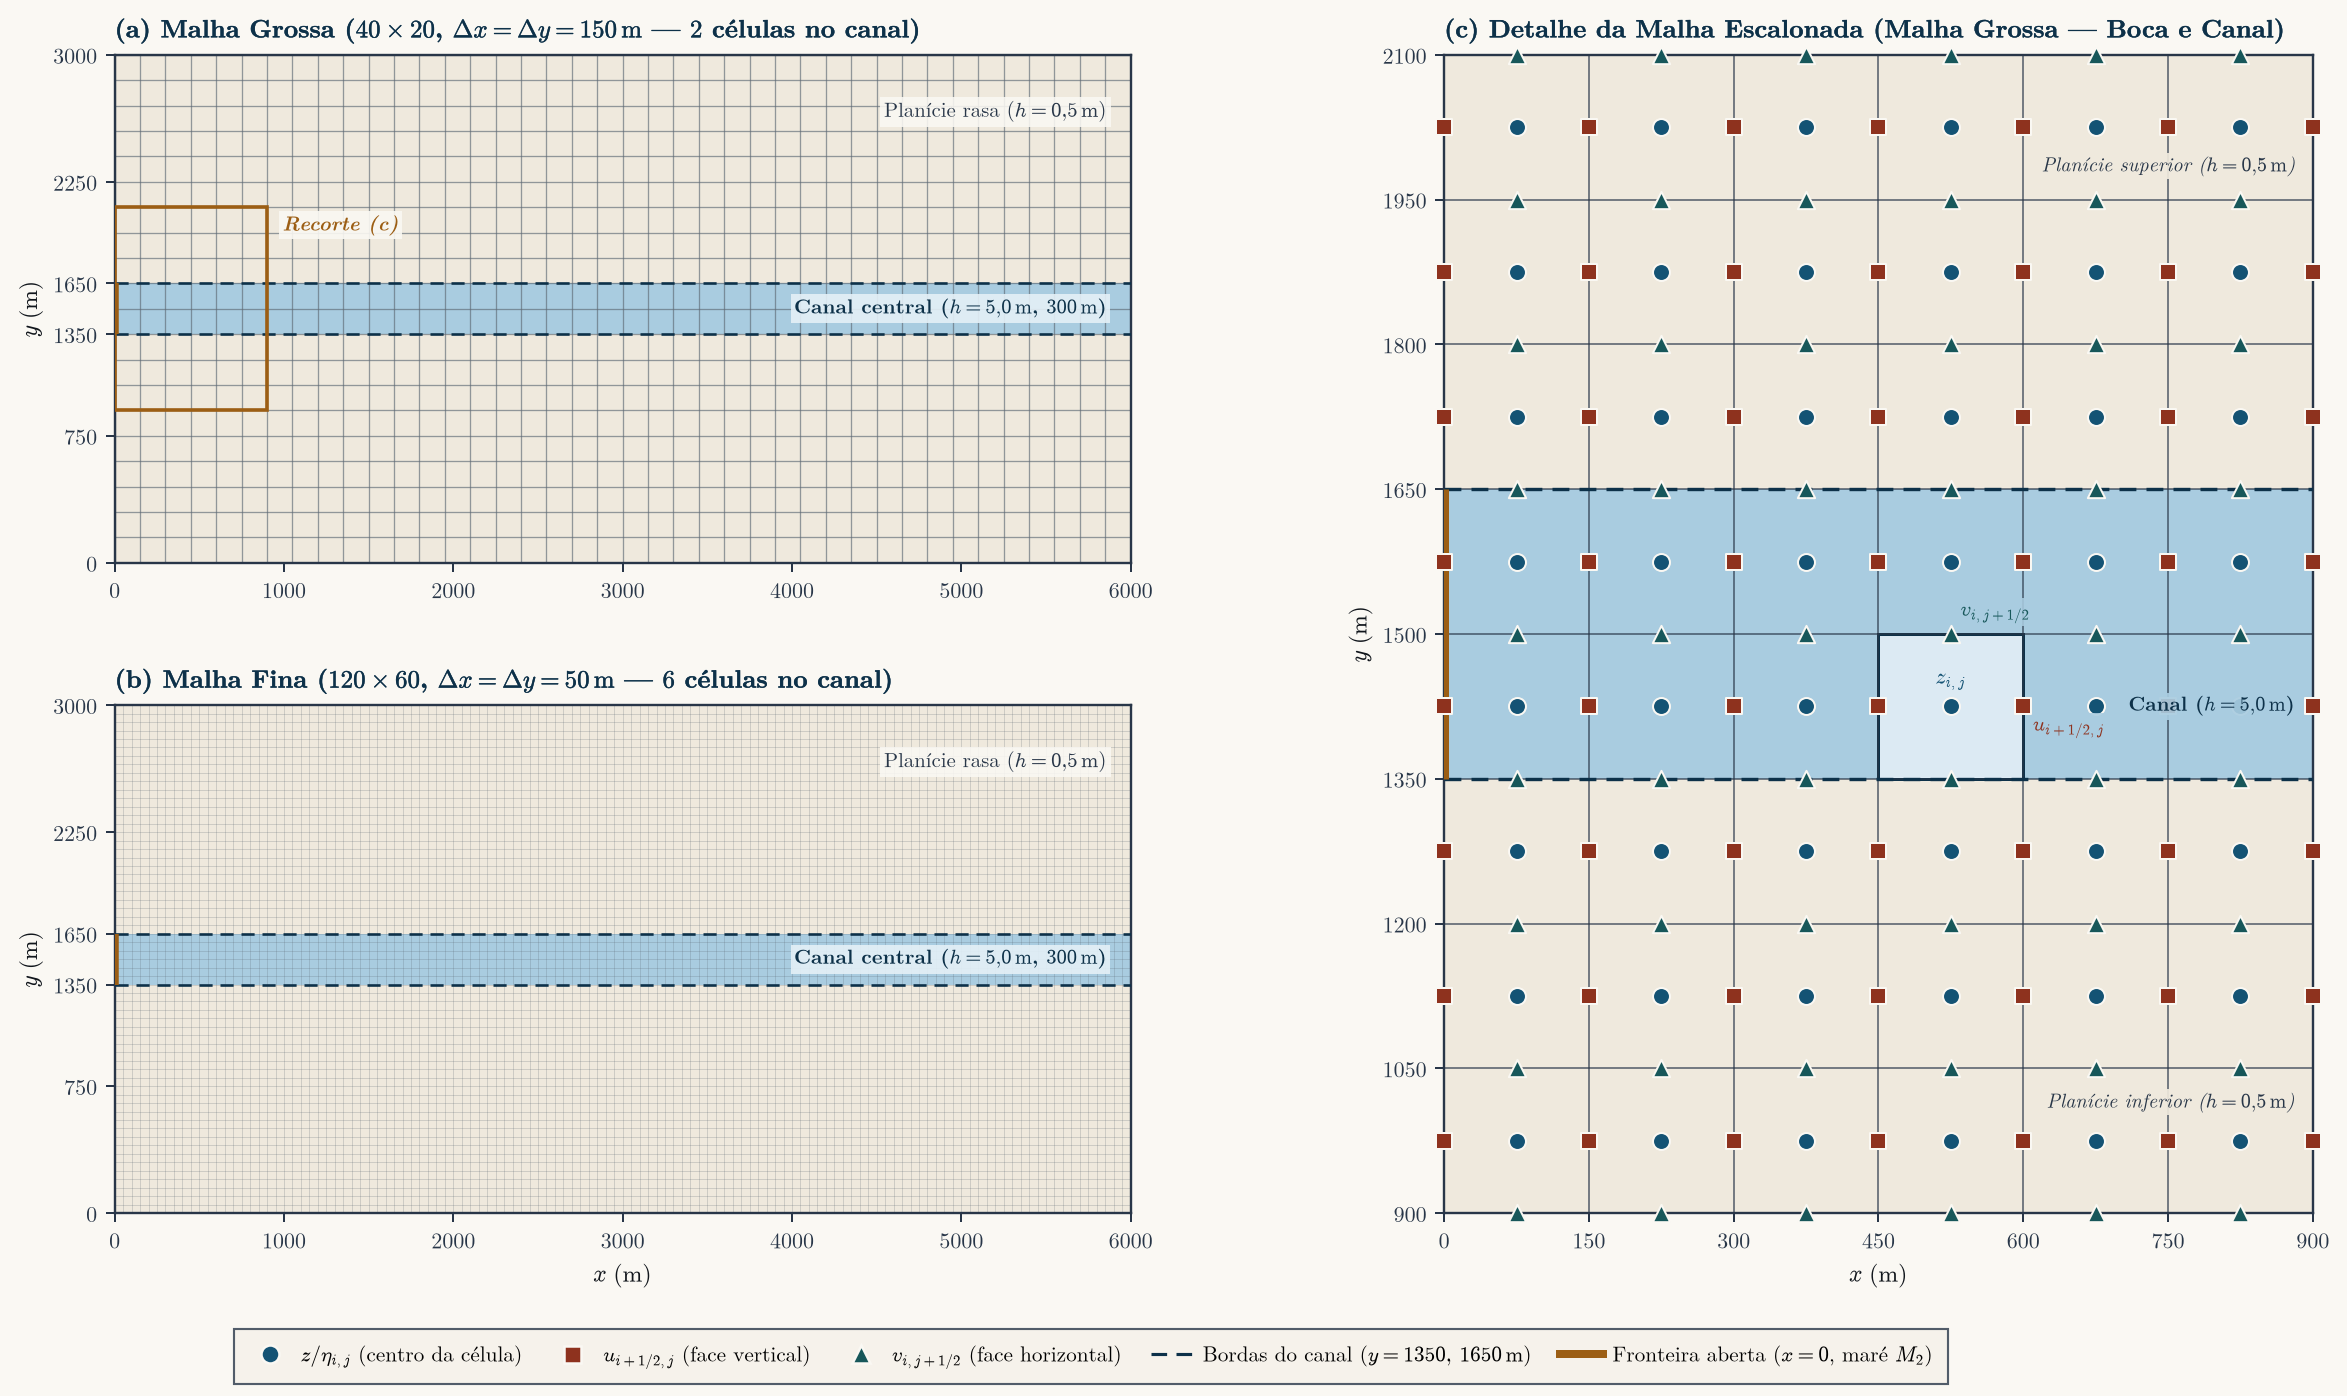

In [26]:
from generate_swe_mesh_discretization_figure import grid_coords, plot_mesh_discretization

plot_mesh_discretization(grid_coarse, grid_fine)

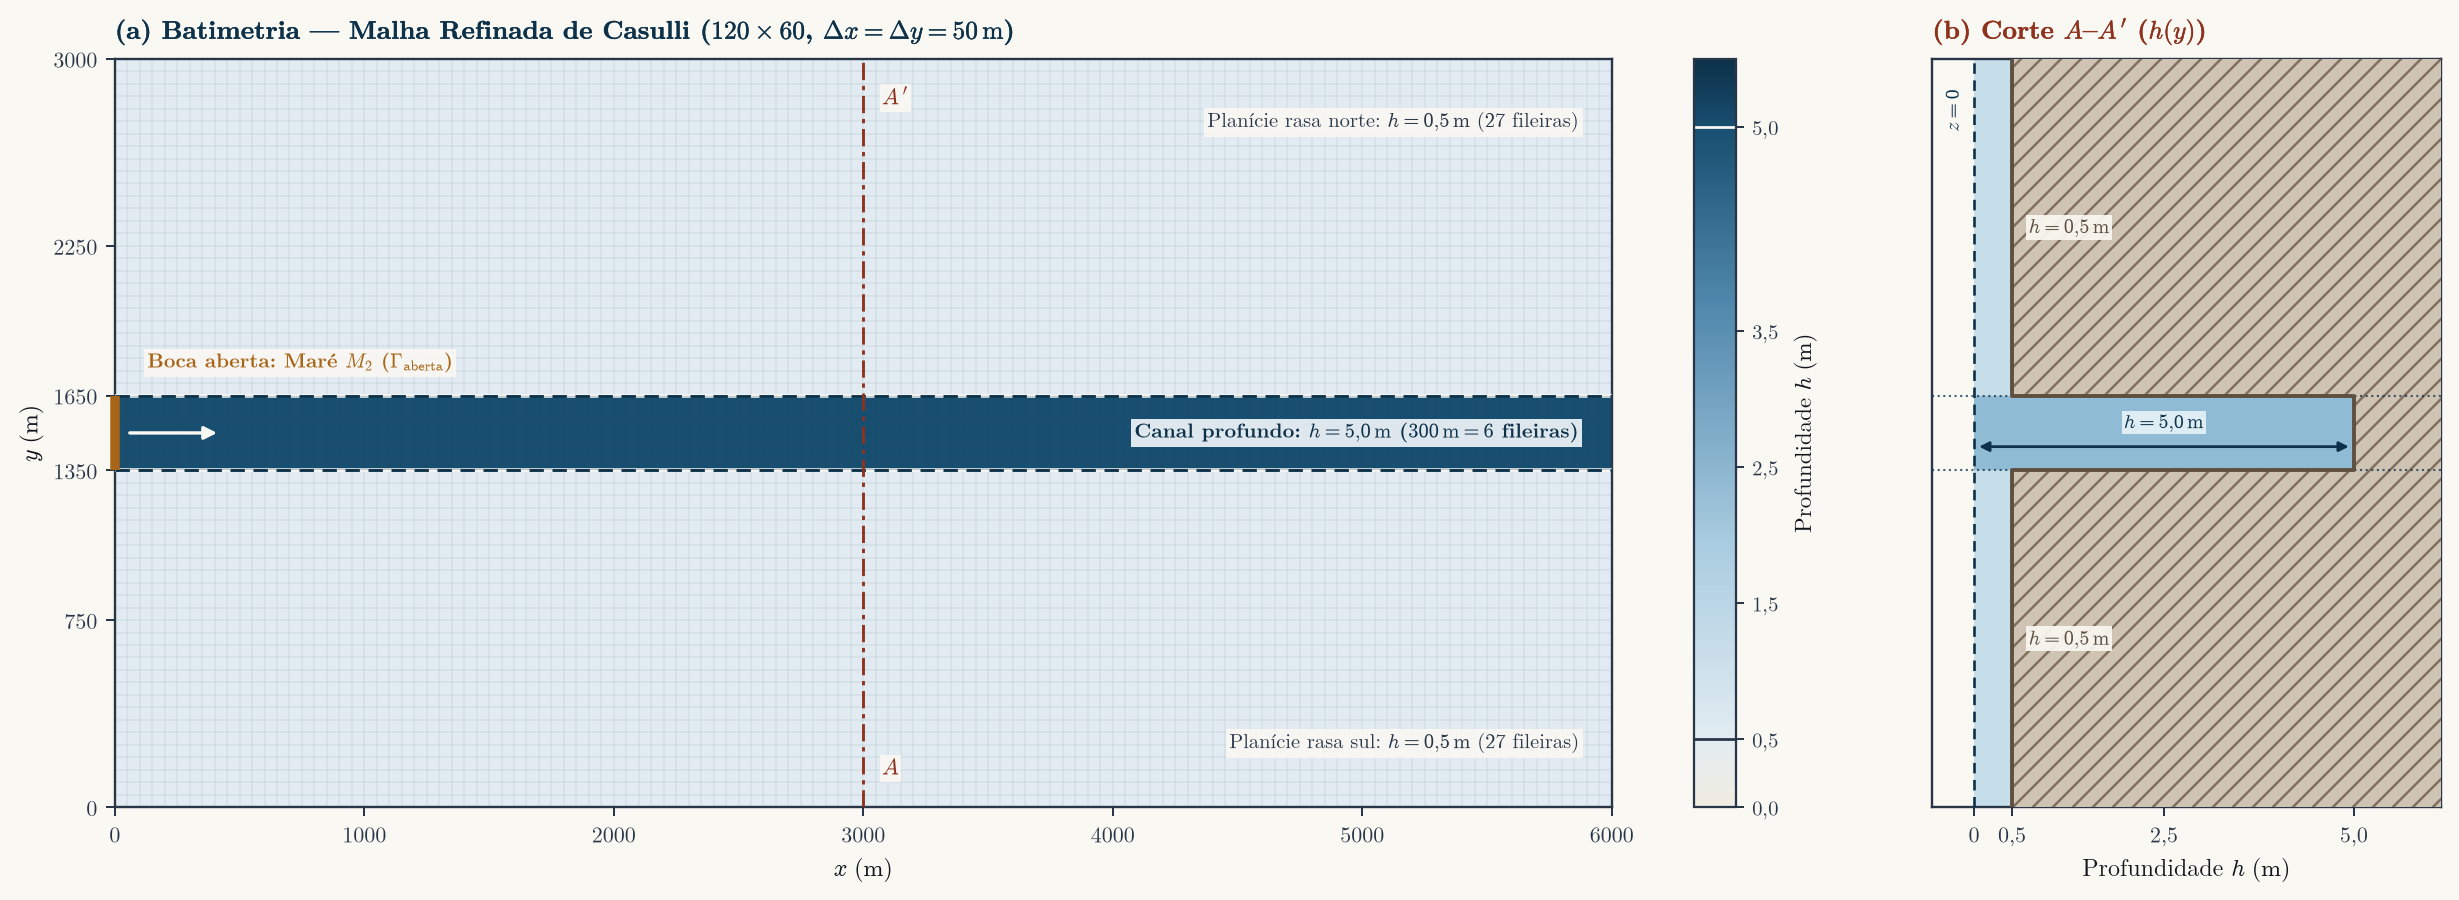

In [27]:
from generate_swe_bathymetry_figure import plot_bathymetry_fine

plot_bathymetry_fine(grid_fine)

## 2.2. Batimetria Discreta

Nesta etapa vamos abordar a questão de as velocidades estarem construídas nas arestas, enquantos as alturas (batimetria) no centro das células. Precisamos representar a profundidade da coluna de água nos mesmos pontos em que estão armazenadas as velocidades.

### 2.2.1. Definição

A batimetria nos centros das células é: 

$$h_{i,j} = h(x_i, y_j) \text{ .}$$

Nas arestas verticais onde $u$ é armazenado:

$$h_{i+1/2, j}^{u} = h(x_{i+1/2}, y_j) \text{,}$$

e nas arestas horizontais, onde $v$ é armazenado:

$$h_{i, j+1/2}^{v} = h(x_i, y_{j+1/2}) \text{.}$$

No problema em questão, a batimetria possui uma descontinuidade nas bordas do canal, indo de $0.5$ para $5.0$ metros:

$$h(y) = \begin{cases} 5.0 \text{, } & 1350\leq y \leq 1650 \text{,} \\ 0.5 \text{, } & \text{caso contrário.} \end{cases}$$

Como essas bordas conincidem exatamente com as arestas horizontais da malha, uma convenção de tratamento para o caso é necessária. Nesta implementação será adotada a avaliação pontual da função de profundidade $h(y)$, atribuindo profundidade de 5 m às arestas situadas exatamente nas bordas do canal. Essa convenção corresponde à definição fechada do intervalo utilizada na geometria do problema. Cassulli estabele que a elevação superficial nas arestas internas é obtida por médias simples dos pontos escalares adjacentes.

In [28]:
# Batimetria nas arestas
def bathymetry_at(X, Y):
    inside_channel = (
        (Y >= y_channel_min) &
        (Y <= y_channel_max)
    )

    return np.where(inside_channel, h_channel, h_shelf).astype(np.float64)

def build_staggered_bathymetry(grid):
    # Profundidade nas arestas verticais (posição de u)
    h_u = bathymetry_at(grid["Xu"], grid["Yu"])

    # Profundidade nas arestas horizontais (posição de v)
    h_v = bathymetry_at(grid["Xv"], grid["Yv"])

    assert h_u.shape == grid["u"].shape
    assert h_v.shape == grid["v"].shape

    grid["h_u"] = h_u
    grid["h_v"] = h_v

    return grid

In [29]:
# Aplicação e testes
grid_coarse = build_staggered_bathymetry(grid_coarse)
grid_fine = build_staggered_bathymetry(grid_fine)

for name, grid in [("Malha Grossa", grid_coarse), ("Malha Fina", grid_fine)]:
    print(f"\n{name}")

    print("h_u:", grid["h_u"].shape)
    print("h_v:", grid["h_v"].shape)

    print("Valores de h_u:", np.unique(grid["h_u"]))
    print("Valores de h_v:", np.unique(grid["h_v"]))

    print(
        "Faces profundas em u:",
        np.count_nonzero(grid["h_u"] == h_channel)
    )

    print(
        "Faces profundas em v:",
        np.count_nonzero(grid["h_v"] == h_channel)
    )


Malha Grossa
h_u: (20, 41)
h_v: (21, 40)
Valores de h_u: [0.5 5. ]
Valores de h_v: [0.5 5. ]
Faces profundas em u: 82
Faces profundas em v: 120

Malha Fina
h_u: (60, 121)
h_v: (61, 120)
Valores de h_u: [0.5 5. ]
Valores de h_v: [0.5 5. ]
Faces profundas em u: 726
Faces profundas em v: 840


Agora precisamos implementar a interpolação da elevação superficial. Casulli utiliza médias simples entre os pontos escalares adjacentes:

$$\eta_{i+1/2, j}^{u} = \frac{\eta_{i,j} + \eta_{i+1, j}}{2}$$
$$\eta_{i, j+1/2}^{v} = \frac{\eta_{i,j} + \eta_{i, j+1}}{2} \text{.}$$

implementado na célula abaixo:

In [30]:
def interpolate_surface_to_faces(grid):
    eta = grid["eta"]

    Ny, Nx = eta.shape

    # Inicialmente as fronteiras ficam sem atribuição
    eta_u = np.full((Ny, Nx + 1), np.nan, dtype=np.float64)
    eta_v = np.full((Ny + 1, Nx), np.nan, dtype=np.float64)

    # Arestas verticais internas
    eta_u[:, 1:-1] = 0.5 * (eta[:, :-1] + eta[:, 1:])

    # Arestas horizontais internas
    eta_v[1:-1, :] = 0.5 * (eta[:-1, :] + eta[1:, :])

    # Profundidade total nas células internas
    H_u = np.full_like(eta_u, np.nan)
    H_v = np.full_like(eta_v, np.nan)

    H_u[:, 1:-1] = (grid["h_u"][:, 1:-1] + eta_u[:, 1:-1])
    H_v[1:-1, :] = (grid["h_v"][1:-1, :] + eta_v[1:-1, :])

    grid["eta_u"] = eta_u
    grid["eta_v"] = eta_v
    grid["H_u"] = H_u
    grid["H_v"] = H_v

    return grid

In [31]:
grid_coarse = interpolate_surface_to_faces(grid_coarse)
grid_fine = interpolate_surface_to_faces(grid_fine)

for name, grid in [
    ("MALHA GROSSA", grid_coarse),
    ("MALHA FINA", grid_fine)
]:
    print(name)

    print("\nDimensões:")
    print("h_u:", grid["h_u"].shape)
    print("h_v:", grid["h_v"].shape)
    print("eta_u:", grid["eta_u"].shape)
    print("eta_v:", grid["eta_v"].shape)

    print("\nProfundidades:")
    print("Valores h_u:", np.unique(grid["h_u"]))
    print("Valores h_v:", np.unique(grid["h_v"]))

    print("\nFaces profundas:")
    print("h_u:", np.count_nonzero(grid["h_u"] == h_channel))
    print("h_v:", np.count_nonzero(grid["h_v"] == h_channel))

    print("\nElevação interpolada:")
    print("eta_u - mínimo:", np.nanmin(grid["eta_u"]))
    print("eta_u - máximo:", np.nanmax(grid["eta_u"]))
    print("eta_v - mínimo:", np.nanmin(grid["eta_v"]))
    print("eta_v - máximo:", np.nanmax(grid["eta_v"]))

    print("\nProfundidade total:")
    print("H_u - mínimo:", np.nanmin(grid["H_u"]))
    print("H_u - máximo:", np.nanmax(grid["H_u"]))
    print("H_v - mínimo:", np.nanmin(grid["H_v"]))
    print("H_v - máximo:", np.nanmax(grid["H_v"]))

    # Verificações estruturais
    assert np.all(grid["h_u"] > 0)
    assert np.all(grid["h_v"] > 0)

    assert np.all(grid["H_u"][:, 1:-1] > 0)
    assert np.all(grid["H_v"][1:-1, :] > 0)

    assert np.all(np.isnan(grid["eta_u"][:, [0, -1]]))
    assert np.all(np.isnan(grid["eta_v"][[0, -1], :]))

    print("\nVerificações: APROVADAS")

MALHA GROSSA

Dimensões:
h_u: (20, 41)
h_v: (21, 40)
eta_u: (20, 41)
eta_v: (21, 40)

Profundidades:
Valores h_u: [0.5 5. ]
Valores h_v: [0.5 5. ]

Faces profundas:
h_u: 82
h_v: 120

Elevação interpolada:
eta_u - mínimo: 0.0
eta_u - máximo: 0.0
eta_v - mínimo: 0.0
eta_v - máximo: 0.0

Profundidade total:
H_u - mínimo: 0.5
H_u - máximo: 5.0
H_v - mínimo: 0.5
H_v - máximo: 5.0

Verificações: APROVADAS
MALHA FINA

Dimensões:
h_u: (60, 121)
h_v: (61, 120)
eta_u: (60, 121)
eta_v: (61, 120)

Profundidades:
Valores h_u: [0.5 5. ]
Valores h_v: [0.5 5. ]

Faces profundas:
h_u: 726
h_v: 840

Elevação interpolada:
eta_u - mínimo: 0.0
eta_u - máximo: 0.0
eta_v - mínimo: 0.0
eta_v - máximo: 0.0

Profundidade total:
H_u - mínimo: 0.5
H_u - máximo: 5.0
H_v - mínimo: 0.5
H_v - máximo: 5.0

Verificações: APROVADAS


Agora temos os campos: $h^{u}$, $h^{v}$, $H^{u}$ e $H^{v}$.

## 2.3. Construção dos Operadores Discretos

Nesta etapa seram construídos manualmente os operadores de diferenças finitas. Serão empregados dois operadores:

1. Gradiente de superfície livre;
2. Divergência dos fluxos.

### 2.3.1. Gradiente Discreto

Considerando a elevação $\eta_{i, j}$ armazenada nos centros das células, na direção $x$ será utilizada diferenças centrais entre células adjacentes:

$$(G_x \eta)_{i+1/2, j} = \frac{\eta_{i+1, j} - \eta_{i, j}}{\Delta x} \text{,}$$

enquanto que na direção $y$:

$$(G_y \eta)_{i, j+1/2} = \frac{\eta_{i, j+1} - \eta_{i, j}}{\Delta y}$$

Estes dois resultados estão posicionados exatamente onde as velocidades são armazenadas, correspondendo à estrutura de malha escalonada apresentada por Casulli. Abaixo há implementação manual da estrutura.

In [32]:
def surface_gradient(grid, eta=None):
    if eta is None:
        eta = grid["eta"]
    
    dx = grid["dx"]
    dy = grid["dy"]

    # Gradiente nas faces verticais internas
    grad_x = (eta[:, 1:] - eta[:, :-1]) / dx

    # Gradiente nas faces horizontais internas
    grad_y = (eta[1:, :] - eta[:-1, :]) / dy

    return grad_x, grad_y

In [34]:
from tests.test_swe_gradients_implementation import test_surface_gradient

test_surface_gradient(grid_coarse, grid_fine, a=2.5e-3, b=-1.2e-3, c=0.4)

[Grossa] OK | gx shape=(20, 39), max_err=1.17e-17 | gy shape=(19, 40), max_err=9.97e-18
[Fina] OK | gx shape=(60, 119), max_err=3.56e-17 | gy shape=(59, 120), max_err=2.54e-17


### 2.3.2. Divergência Discreta

Considerando os fluxos $q_x = H_u$ e $q_y = H_v$, ambos armazenados nas faces, a divergência será calculada nos centros das células por:

$$(D\mathbf{q})_{i,j} = \frac{q_{x, i+1/2, j} - q_{x, i-1/2, j}}{\Delta x} + \frac{q_{y, i, j+1/2} - q_{y, i, j-1/2}}{\Delta y}$$

Podemos observar que:

* O gradiente transforma uma variável escalar em componentes nas arestas, e
* A divergência transforma fluxos nas arestas em uma variável escalar nos centros da célula.

In [35]:
def flux_divergence(grid, qx, qy):
    dx = grid["dx"]
    dy = grid["dy"]

    Ny = grid["Ny"]
    Nx = grid["Nx"]

    assert qx.shape == (Ny, Nx + 1)
    assert qy.shape == (Ny + 1, Nx)

    div_x = (qx[:, 1:] - qx[:, :-1]) / dx
    div_y = (qy[1:, :] - qy[:-1, :]) / dy

    divergence = div_x + div_y

    return divergence

In [38]:
from tests.test_swe_divergence_implementation import test_surface_divergence

test_surface_divergence(grid_coarse, grid_fine, a=2.0, b=3.0)

[Grossa] OK | div shape=(20, 40) | max_err=0.00e+00 | cons_err=0.00e+00
[Fina] OK | div shape=(60, 120) | max_err=0.00e+00 | cons_err=0.00e+00


# Etapa 3 - Construção do Sistema Linear

# Etapa 4 - Implementação dos Solucionadores

# Etapa 5 - Reprodução numérica de Casulli

# Etapa 6 - Implementação em JAX

# Etapa 7 - Análise espectral e escalabilidade

Experimento A — Refinamento de malha

Primeiro, reproduzir as duas malhas do artigo:
\[
40\times20
\]
\[
120\times60
\]
Depois, ampliar progressivamente mantendo a proporção física de 2:1:
\[
120\times240,\quad
240\times480,\quad
480\times960.
\]
As duas primeiras configurações reproduzem o benchmark; as demais representam nosso experimento de escalabilidade.

Experimento B — Número de Courant

Investigar:
\[
C_r=2,\quad 8,\quad 20.
\]
Vamos variar o passo temporal, mantendo a configuração espacial fixa.

Experimento C — Precondicionamento

Comparar:
- CG sem precondicionamento.
- PCG com Jacobi.
Experimento D — Arquitetura computacional

Comparar:
- NumPy em CPU.
- JAX em CPU.
- JAX em GPU.
Experimento E — Representação do operador

Comparar:
- Armazenamento DIA.
- Operador Matrix-Free.
CSR pode ser acrescentado se não comprometer o cronograma.

Para todos os experimentos, avaliaremos tempo de execução, consumo de memória, número de iterações, resíduos e precisão.

# Etapa 8 - Discussão dos resultados

Contribuição pode ser uma investigação computacional bem delimitada:

Implementação e análise comparativa de métodos semi-implícitos para as equações bidimensionais de águas rasas, com avaliação de condicionamento espectral e desempenho computacional em arquiteturas CPU/GPU.

O trabalho conecta:
1. Equações diferenciais parciais e discretização numérica.
2. Sistemas lineares esparsos.
3. Métodos iterativos e diretos.
4. Precondicionamento e teoria espectral.
5. Programação científica e arquiteturas paralelas.
É um projeto coerente com Matemática Aplicada e Ciência da Computação.